# SCU35 Ethernet crypto: program, test and compare
This notebook uses the **Ethernet IPI design**: MicroBlaze V, 128 KiB local BRAM, AXI Ethernet Lite, AXI Timer and PMC Bridge. It sends actual host payloads over the physical Ethernet link.

Configure the parent lab config.json, connect the RJ45 cable, and set the host adapter to 192.168.10.1/24 (board 192.168.10.2). Select the lab Python environment. Close other UART terminals and restore/stop any running dashboard first.

**LIVE=True programs the Ethernet PDI, captures UART, runs packet tests and benchmarks, then restores the configured recovery PDI.** No separate manual programming or ELF download is needed. LIVE=False freshly verifies the saved capture and measures Python, without touching the board. No flash/eFUSE writes. The AES key 00..1f is public diagnostic data, not a provisioned secure channel.

**Saved execution:** 2026-10-26T04:41:49.736037+00:00. Fresh physical-Ethernet LMS/HSS and packet tests, Python timings, volatile programming and verified recovery. Executed with LIVE=True; the portable default is restored to False for the next run.

In [1]:
from pathlib import Path
import sys, json, hashlib, time, statistics, os
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
HERE = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base,base/'ethernet',base/'scu35/ethernet') if (p/'launch.py').is_file()),None)
assert HERE is not None, 'Open this notebook inside the repository'
sys.path.insert(0,str(HERE));sys.path.insert(0,str(HERE.parent))
from lab import config
from launch import test
from verify_capture import verify
c=config()
print('Python:',sys.executable)


Python: C:\aiup\pubvenv\Scripts\python.exe


In [2]:
LIVE = False
COUNT = 50  # Per operation/size; nine timed groups = 450 exchanges
if LIVE:
    SESSION = test(c=c,count=COUNT)
    CAPTURE = SESSION/'ethernet/results.json'
    meta=json.loads((SESSION/'session.json').read_text())
    assert meta['hardware_pass'] and meta['recovery_pass'],meta
    print('FRESH PHYSICAL ETHERNET + RECOVERY PASS:',SESSION)
else:
    SESSION=None
    CAPTURE=HERE/'evidence/run4/ethernet/results.json'
    print('RECORDED PHYSICAL ETHERNET; freshly verifying captured bytes:',CAPTURE)
verification=verify(CAPTURE)
report=json.loads(CAPTURE.read_text())
assert report['overall']=='PASS'
print('Functional checks:',len(report['checks']))
display(pd.DataFrame(report['checks'].items(),columns=['check','result']))


Programming Ethernet PDI, testing payloads, then verifying recovery.


Evidence: C:\aiup\s35p2\ethernet_runs\test_20261025_224103_995275


 


E35_START,2,128KiB,100MHz,LMS_HSS_ETHERNET


E35_CRYPTO_INIT,0


...

OFFLINE_ETHERNET_CAPTURE_PASS: 20 exact payload/hash cases; bad-tag and replay response records; unique response nonces


 


ETH_HARDWARE_AND_RECOVERY_PASS C:\aiup\s35p2\ethernet_runs\test_20261025_224103_995275


FRESH PHYSICAL ETHERNET + RECOVERY PASS: C:\aiup\s35p2\ethernet_runs\test_20261025_224103_995275
OFFLINE_ETHERNET_CAPTURE_PASS: 20 exact payload/hash cases; bad-tag and replay response records; unique response nonces
Functional checks: 24


,check,result
0,plain_16,PASS
1,encrypt_16,PASS
2,authenticated_echo_16,PASS
3,SHA3-256_16,PASS
4,SHAKE-256_16,PASS
5,plain_64,PASS
6,encrypt_64,PASS
7,authenticated_echo_64,PASS
8,SHA3-256_64,PASS
9,SHAKE-256_64,PASS


## Physical-link benchmarks
Host RTT measures UDP send-to-receive, including the network and device. Host request encryption and response verification are outside RTT. Sequential payload MB/s is not saturated link bandwidth or isolated AES throughput. Separate rows show the transport baseline, encrypted response and authenticated decrypt/encrypt echo.

,method,payload_bytes,packets,median_rtt_us,p95_rtt_us,sequential_payload_MBps
0,UDP plaintext echo,64,50,322.15,347.8,0.195849
1,UDP plaintext echo,256,50,452.80,481.7,0.558457
2,UDP plaintext echo,1024,50,986.20,1038.7,1.032352
3,PMC encrypt response,64,50,415.60,437.7,0.153760
4,PMC encrypt response,256,50,539.15,566.2,0.473322
5,PMC encrypt response,1024,50,1049.35,1107.8,0.970721
6,PMC decrypt + encrypt echo,64,50,475.05,499.5,0.133721
7,PMC decrypt + encrypt echo,256,50,606.55,632.6,0.420474
8,PMC decrypt + encrypt echo,1024,50,1115.55,1163.5,0.913667


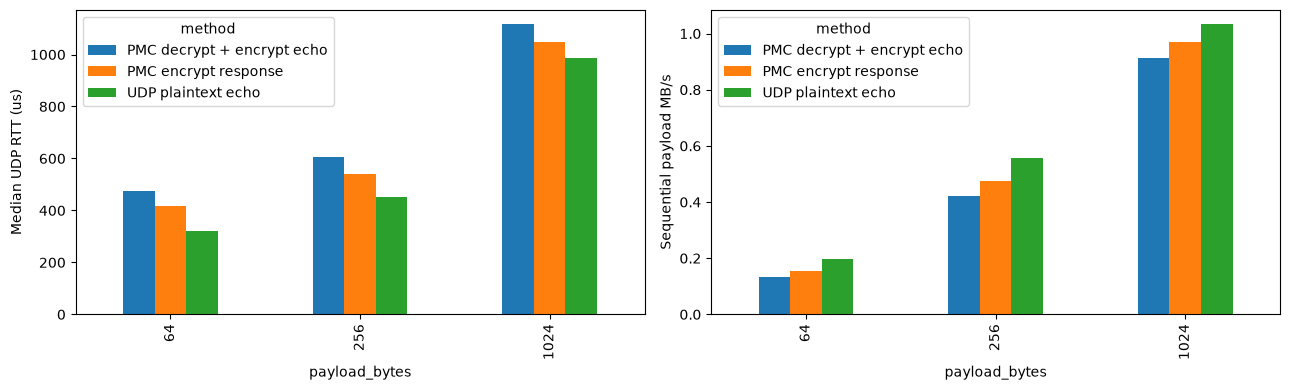

In [3]:
network=pd.DataFrame(report['benchmarks'])
display(network)
fig,axes=plt.subplots(1,2,figsize=(13,4))
network.pivot(index='payload_bytes',columns='method',values='median_rtt_us').plot.bar(ax=axes[0])
axes[0].set_ylabel('Median UDP RTT (us)')
network.pivot(index='payload_bytes',columns='method',values='sequential_payload_MBps').plot.bar(ax=axes[1])
axes[1].set_ylabel('Sequential payload MB/s')
fig.tight_layout();display(fig);plt.close(fig)


## Fresh Python crypto timing
These host-only library timings exclude network, device and transport costs. They are intentionally separate from the UDP RTT table. Exact captured SHA/AES responses, changed-tag rejection and replay records were verified above. Fresh AES encryptions below use unique nonces.

In [4]:
aes=AESGCM(bytes(range(32)));host_rows=[]
for size in [16,64,256,1024]:
    payload=bytes((i*17+size)%256 for i in range(size))
    prefix=os.urandom(8)
    for method in ['SHA3-256','SHAKE-256','AES-GCM-ENC','AES-GCM-DEC']:
        iv=os.urandom(12);ct=aes.encrypt(iv,payload,None);samples=[]
        for iteration in range(500):
            nonce=prefix+iteration.to_bytes(4,'big')
            started=time.perf_counter_ns()
            if method=='SHA3-256':value=hashlib.sha3_256(payload).digest()
            elif method=='SHAKE-256':value=hashlib.shake_256(payload).digest(32)
            elif method=='AES-GCM-ENC':value=aes.encrypt(nonce,payload,None)
            else:value=aes.decrypt(iv,ct,None)
            samples.append((time.perf_counter_ns()-started)/1000)
        if method=='AES-GCM-DEC':assert value==payload
        host_rows.append({'method':method,'payload_bytes':size,'Python median us':statistics.median(samples),
                          'Python mean us':statistics.mean(samples),'samples':len(samples)})
display(pd.DataFrame(host_rows))
if SESSION:
    (SESSION/'python_timings.json').write_text(json.dumps(host_rows,indent=2))


,method,payload_bytes,Python median us,Python mean us,samples
0,SHA3-256,16,1.5,1.5004,500
1,SHAKE-256,16,1.5,1.5670,500
2,AES-GCM-ENC,16,1.4,1.3746,500
3,AES-GCM-DEC,16,1.4,1.3954,500
4,SHA3-256,64,1.5,1.7488,500
5,SHAKE-256,64,1.5,1.5528,500
6,AES-GCM-ENC,64,1.4,1.4144,500
7,AES-GCM-DEC,64,1.7,1.7650,500
8,SHA3-256,256,1.8,1.8018,500
9,SHAKE-256,256,1.8,1.8358,500


## Live LMS/HSS over Ethernet
The host uploads actual signature, message and public-key bytes in five authenticated chunks. Verification runs on MicroBlaze V with the AMD XilSecure library and hardened PMC SHAKE/DMA. Public AMD H5/W2 vectors, 56-byte messages, one-level HSS. Every device decision is independently checked by Python.

Upload and AES/network costs are separate from the device verification API interval. Negative cases measure rejection work. No signing key/state is present on the board.

samples  SCU35_API_median_us  Python_median_us  \
algorithm    case                                                            
HSS-SHAKE256 bad_key              5             11839.07             532.0   
             bad_message          5             12315.01             595.4   
             bad_signature        5             12642.65             537.3   
             valid                5             11839.07             535.5   
LMS-SHAKE256 bad_key              5             12597.73             545.6   
             bad_message          5             12418.47             541.6   
             bad_signature        5             11763.20             506.5   
             valid                5             12597.94             603.3   

                            verify_request_RTT_median_us  accepted  \
algorithm    case                                                    
HSS-SHAKE256 bad_key                             12441.9     False   
             bad_message                         12908.7     False   
             bad_signature                       13269.9     False   
             valid                               12505.5      True   
LMS-SHAKE256 bad_key                             13229.4     False   
             bad_message                         13063.4     False   
             bad_signature                       12394.0     False   
             valid                               13159.3      True   

                            API_operations_per_s  
algorithm    case                                 
HSS-SHAKE256 bad_key                   84.466094  
             bad_message               81.201721  
             bad_signature             79.097341  
             valid                     84.466094  
LMS-SHAKE256 bad_key                   79.379380  
             bad_message               80.525218  
             bad_signature             85.010881  
             valid                     79.378057

,guard,status,expected_status
0,wrong_transfer_id,5,5
1,pq_replayed_command,3,3
2,pq_bad_gcm_tag,2,2
3,incomplete_upload,5,5
4,upload_overrun,5,5
5,unsupported_parameter_profile,5,5


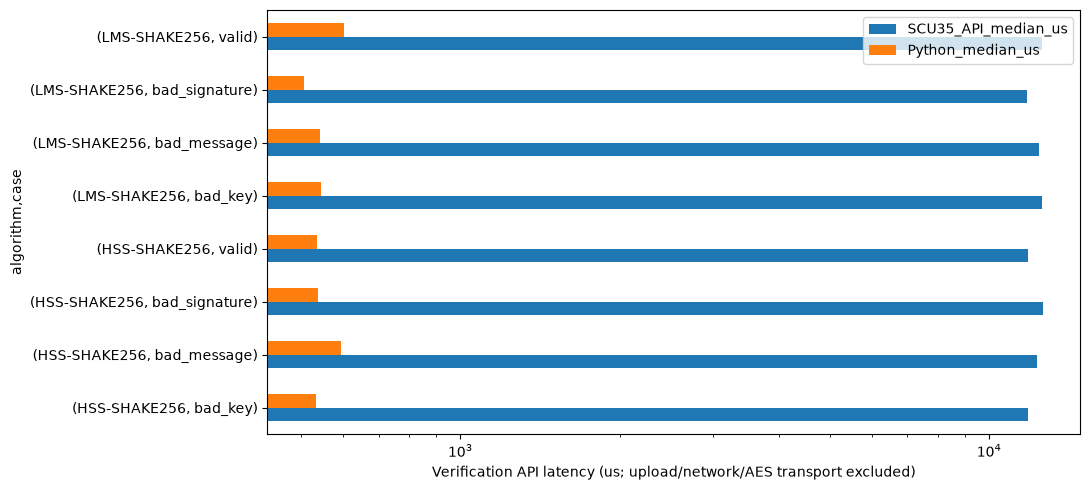

In [5]:
PQ_CAPTURE = SESSION/'pq.json' if SESSION else HERE/'evidence/run4/pq.json'
pq=json.loads(PQ_CAPTURE.read_text())
assert pq['overall']=='PASS'
pq_rows=pd.DataFrame(pq['rows'])
assert all(pq_rows.result_matches_python)
summary=pq_rows.groupby(['algorithm','case']).agg(
    samples=('device_verify_us','count'), SCU35_API_median_us=('device_verify_us','median'),
    Python_median_us=('python_verify_us','median'), verify_request_RTT_median_us=('rtt_us','median'),
    accepted=('accepted','all'))
summary['API_operations_per_s']=1e6/summary['SCU35_API_median_us']
display(summary)
display(pd.DataFrame(pq['guards']))
assert all(g['status']==g['expected_status'] for g in pq['guards'])
fig,ax=plt.subplots(figsize=(11,5))
summary[['SCU35_API_median_us','Python_median_us']].plot.barh(ax=ax,logx=True)
ax.set_xlabel('Verification API latency (us; upload/network/AES transport excluded)')
fig.tight_layout();display(fig);plt.close(fig)


## Start the live HTML dashboard
From the lab directory, using the same Python environment/config:
```text
python ethernet/launch.py dashboard
```
The launcher programs the Ethernet image and retains its board reservation while running. Open the printed localhost URL. Buttons select plain UDP, AES-GCM, SHA3 and SHAKE; payload sizes, pause/resume, and tamper/replay tests update the real traffic and plots.

Use **Restore board & stop traffic** when finished. Do not run this notebook's LIVE cell while the dashboard owns the board. The highlighted LMS/HSS buttons now upload public signature/message/key data and run actual verification on MicroBlaze V plus hardened PMC SHAKE. Valid and modified-input cases are live. Only the public AMD H5/W2 profile and one-level HSS are supported; this is runtime verification, not secure boot.

GitHub Pages hosts the lesson and screenshots; the live dashboard runs locally with the connected SCU35.